# How the U.S. Population Changed by Age and Sex, 2020 → 2025

**Data:** U.S. Census Bureau, *Annual Estimates of the Resident Population for Selected Age Groups by Sex for the United States: April 1, 2020 to July 1, 2025* (file `nc-est2025-agesex.xlsx`, released June 2026).

**What this notebook does**
1. Loads and tidies the Census table.
2. Runs a short exploratory data analysis (EDA).
3. Builds two charts for a general audience:
   - side-by-side **population pyramids** for 2020 and 2025
   - a **diverging bar chart** of the percent change in each age group
4. Summarizes the findings.

## 1. Setup
Only three libraries are needed: `pandas` for tables, `numpy` for math, and `matplotlib` for charts (`openpyxl` must also be installed so pandas can read `.xlsx` files).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if abs(v) >= 1000 else f"{v:,.1f}")

FILE = "nc-est2025-agesex.xlsx"

# Colors used in every chart (colorblind-safe blue/orange pair)
MEN_COLOR    = "#2a78d6"  # blue
WOMEN_COLOR  = "#eb6834"  # orange
GROW_COLOR   = "#2a78d6"  # blue   = population grew
SHRINK_COLOR = "#eb6834"  # orange = population shrank
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "font.size": 11,
    "axes.edgecolor": INK_SOFT,
    "axes.labelcolor": INK,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

## 2. Understand the file's structure
The spreadsheet is a formatted Census table, not a tidy dataset. Looking at the raw sheet:

| Rows (0-based) | What they hold |
|---|---|
| 0–1 | Accessibility note and table title |
| 2–4 | **Three header rows**: time period → year → sex (*Both Sexes, Male, Female*) |
| 5 | **Total** population |
| 6–23 | **18 five-year age groups** (Under 5 … 85 and over) |
| 25–33 | Broader groups (Under 18, 18–64, 65+, and sub-groups) |
| 35–37 | Other groups (16+, 18+, 15–44) |
| 39 | **Median age** |
| 40–45 | Notes, citation, source |

Columns: column A is the age label; then 3 columns (*Both, Male, Female*) for each of **7 time points**: the April 1, 2020 estimates base, then July 1 of 2020, 2021, 2022, 2023, 2024 and 2025. Age labels start with a `.` that we remove.

In [2]:
raw = pd.read_excel(FILE, header=None)
print("Raw sheet size (rows, columns):", raw.shape)
raw.head(8)

Raw sheet size (rows, columns): (46, 22)


,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
0,table with row headers in column A and column ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Annual Estimates of the Resident Population fo...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Age,"April 1, 2020 Estimates Base",NaN,NaN,Population Estimate (as of July 1),NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,2020,NaN,NaN,2021,NaN,NaN,...,NaN,2023,NaN,NaN,2024,NaN,NaN,2025,NaN,NaN
4,NaN,Both Sexes,Male,Female,Both Sexes,Male,Female,Both Sexes,Male,Female,...,Female,Both Sexes,Male,Female,Both Sexes,Male,Female,Both Sexes,Male,Female
5,Total,331516113,162758499,168757614,331578104,162780726,168797378,332100166,162980790,169119376,...,170128220,336755052,165233378,171521674,340003797,166868649,173135148,341784857,167737525,174047332
6,.Under 5 years,19226271,9823770,9402501,19133927,9775549,9358378,18753367,9583226,9170141,...,9126327,18606537,9504784,9101753,18584735,9496353,9088382,18491867,9449992,9041875
7,.5 to 9 years,20120958,10286089,9834869,20088796,10270260,9818536,20017108,10230021,9787087,...,9785709,20009812,10224110,9785702,19978615,10201396,9777219,19787721,10101519,9686202


### Tidy the table
We turn the three header rows into proper column names (period, sex) and keep only rows that contain numbers.

In [3]:
# Header row 3 holds the year (only above the first column of each group), row 4 the sex
period = raw.iloc[3, 1:].copy()
period.iloc[0:3] = "Apr 2020 base"          # first three columns are the April 1, 2020 base
period = period.ffill().astype(str).str.replace(r"\.0$", "", regex=True)
sex = raw.iloc[4, 1:].replace({"Both Sexes": "Both", "Male": "Men", "Female": "Women"})

table = raw.iloc[5:40, :].dropna(subset=[1])            # rows with numbers only
table = table.set_index(table[0].str.lstrip(".")).iloc[:, 1:]
table.index.name = "age_group"
table.columns = pd.MultiIndex.from_arrays([period, sex], names=["period", "sex"])
table = table.apply(pd.to_numeric)

print("Time periods:", list(table.columns.get_level_values("period").unique()))
table.iloc[:, -3:]   # preview: the 2025 columns

Time periods: ['Apr 2020 base', '2020', '2021', '2022', '2023', '2024', '2025']


period                    2025                        
sex                       Both         Men       Women
age_group                                             
Total              341,784,857 167,737,525 174,047,332
Under 5 years       18,491,867   9,449,992   9,041,875
5 to 9 years        19,787,721  10,101,519   9,686,202
10 to 14 years      20,620,105  10,539,273  10,080,832
15 to 19 years      22,115,280  11,323,927  10,791,353
20 to 24 years      22,943,234  11,723,186  11,220,048
25 to 29 years      23,342,365  11,815,783  11,526,582
30 to 34 years      23,221,682  11,660,125  11,561,557
35 to 39 years      23,171,303  11,548,851  11,622,452
40 to 44 years      22,149,712  10,967,569  11,182,143
45 to 49 years      20,356,102  10,013,169  10,342,933
50 to 54 years      19,778,682   9,674,842  10,103,840
55 to 59 years      20,112,899   9,777,218  10,335,681
60 to 64 years      21,076,817  10,108,530  10,968,287
65 to 69 years      19,921,459   9,388,985  10,532,474
70 to 74 years      16,766,692   7,734,018   9,032,674
75 to 79 years      12,959,591   5,835,979   7,123,612
80 to 84 years       7,928,310   3,407,808   4,520,502
85 years and over    7,041,036   2,666,751   4,374,285
Under 18 years      72,021,348  36,804,016  35,217,332
Under 5 years       18,491,867   9,449,992   9,041,875
5 to 13 years       36,232,804  18,504,803  17,728,001
14 to 17 years      17,296,677   8,849,221   8,447,456
18 to 64 years     205,146,421 101,899,968 103,246,453
18 to 24 years      31,936,859  16,333,881  15,602,978
25 to 44 years      91,885,062  45,992,328  45,892,734
45 to 64 years      81,324,500  39,573,759  41,750,741
65 years and over   64,617,088  29,033,541  35,583,547
16 years and over  278,615,174 135,462,971 143,152,203
18 years and over  269,763,509 130,933,509 138,830,000
15 to 44 years     136,943,576  69,039,441  67,904,135
Median age (years)        39.4        38.1        40.7

Next we pull out the **18 five-year age groups** (the building blocks of a population pyramid) into a long, tidy table: one row per age group × year × sex. We also give the age groups short, friendly labels (e.g. *“Under 5 years” → “0–4”*).

In [4]:
five_year = table.iloc[1:19]     # the 18 five-year groups that sit right under "Total"

def short_label(s):
    if s.startswith("Under"):
        return "0–4"
    if "and over" in s:
        return s.split()[0] + "+"
    lo, _, hi = s.replace(" years", "").split()
    return f"{lo}–{hi}"

AGE_ORDER = [short_label(a) for a in five_year.index]

tidy = (five_year.rename(index=short_label)
        .stack(["period", "sex"], future_stack=True)
        .rename("population").reset_index())
tidy.head(10)

,age_group,period,sex,population
0,0–4,Apr 2020 base,Both,"19,226,271"
1,0–4,Apr 2020 base,Men,"9,823,770"
2,0–4,Apr 2020 base,Women,"9,402,501"
3,0–4,2020,Both,"19,133,927"
4,0–4,2020,Men,"9,775,549"
5,0–4,2020,Women,"9,358,378"
6,0–4,2021,Both,"18,753,367"
7,0–4,2021,Men,"9,583,226"
8,0–4,2021,Women,"9,170,141"
9,0–4,2022,Both,"18,657,930"


## 3. Exploratory data analysis
### 3a. Data quality checks
- Are any values missing?
- Do the 18 age groups add up to the reported total for every year and sex?

In [5]:
print("Missing values in the five-year table:", int(five_year.isna().sum().sum()))

check = five_year.sum() - table.loc["Total"]
print("Largest gap between sum of age groups and reported total:", int(check.abs().max()))

Missing values in the five-year table: 0
Largest gap between sum of age groups and reported total: 0


**Result:** no missing values, and the age groups add up exactly to the totals, so the table is complete and internally consistent.

### 3b. Total population and median age over time
*Note:* to compare like with like, the rest of the notebook compares **July 1, 2020** with **July 1, 2025** (exactly five years apart). The April 1, 2020 “base” is a separate starting point used by the Census Bureau.

In [6]:
overview = pd.DataFrame({
    "Total (millions)": table.loc["Total"].xs("Both", level="sex") / 1e6,
    "Men (millions)":   table.loc["Total"].xs("Men", level="sex") / 1e6,
    "Women (millions)": table.loc["Total"].xs("Women", level="sex") / 1e6,
    "Median age":       table.loc["Median age (years)"].xs("Both", level="sex"),
})
overview["Women per 100 men"] = overview["Women (millions)"] / overview["Men (millions)"] * 100
overview.round(2)

,Total (millions),Men (millions),Women (millions),Median age,Women per 100 men
period,,,,,
Apr 2020 base,331.5,162.8,168.8,38.6,103.7
2020,331.6,162.8,168.8,38.7,103.7
2021,332.1,163.0,169.1,38.9,103.8
2022,334.0,163.9,170.1,39.0,103.8
2023,336.8,165.2,171.5,39.1,103.8
2024,340.0,166.9,173.1,39.2,103.8
2025,341.8,167.7,174.1,39.4,103.8


In [7]:
tot = table.loc["Total"].xs("Both", level="sex")
print(f"Population grew by {tot['2025'] - tot['2020']:,.0f} people "
      f"({(tot['2025'] / tot['2020'] - 1) * 100:.1f}%) from July 2020 to July 2025.")

Population grew by 10,206,753 people (3.1%) from July 2020 to July 2025.


### 3c. Broad life stages: children, working-age adults, older adults

In [8]:
broad = table.loc[["Under 18 years", "18 to 64 years", "65 years and over"]].xs("Both", level="sex", axis=1)
stages = pd.DataFrame({
    "2020 (millions)": broad["2020"] / 1e6,
    "2025 (millions)": broad["2025"] / 1e6,
    "Change (%)": (broad["2025"] / broad["2020"] - 1) * 100,
    "Share of all people 2020 (%)": broad["2020"] / tot["2020"] * 100,
    "Share of all people 2025 (%)": broad["2025"] / tot["2025"] * 100,
})
stages

,2020 (millions),2025 (millions),Change (%),Share of all people 2020 (%),Share of all people 2025 (%)
age_group,,,,,
Under 18 years,73.7,72.0,-2.2,22.2,21.1
18 to 64 years,202.0,205.1,1.6,60.9,60.0
65 years and over,55.9,64.6,15.5,16.9,18.9


### 3d. Summary statistics for the 18 age groups

In [9]:
both = five_year.xs("Both", level="sex", axis=1)[["2020", "2025"]].rename(index=short_label)
(both / 1e6).describe().rename(columns=lambda c: f"{c} (millions)")

period,2020 (millions),2025 (millions)
count,18.0,18.0
mean,18.4,19.0
std,5.4,4.9
min,6.3,7.0
25%,18.5,18.8
50%,20.5,20.2
75%,21.9,22.1
max,22.5,23.3


**EDA takeaways**
- The U.S. grew by about **10.2 million people (+3.1%)** between July 2020 and July 2025.
- The **median age rose from 38.7 to 39.4 years**: half the country is now older than 39.4.
- The number of **people 65 and older jumped about 15%**, while the number of **children under 18 fell about 2%**.
- Women outnumber men overall, mostly because women live longer (the gap is largest in the oldest age groups).

## 4. Visualization 1 — Population pyramids, 2020 vs 2025
**How to read it:** each horizontal bar is one 5-year age group, youngest at the bottom and oldest at the top. Men extend to the left, women to the right. The longer the bar, the more people in that age group. In the 2025 chart, a dashed black outline shows the 2020 shape so you can see what changed.

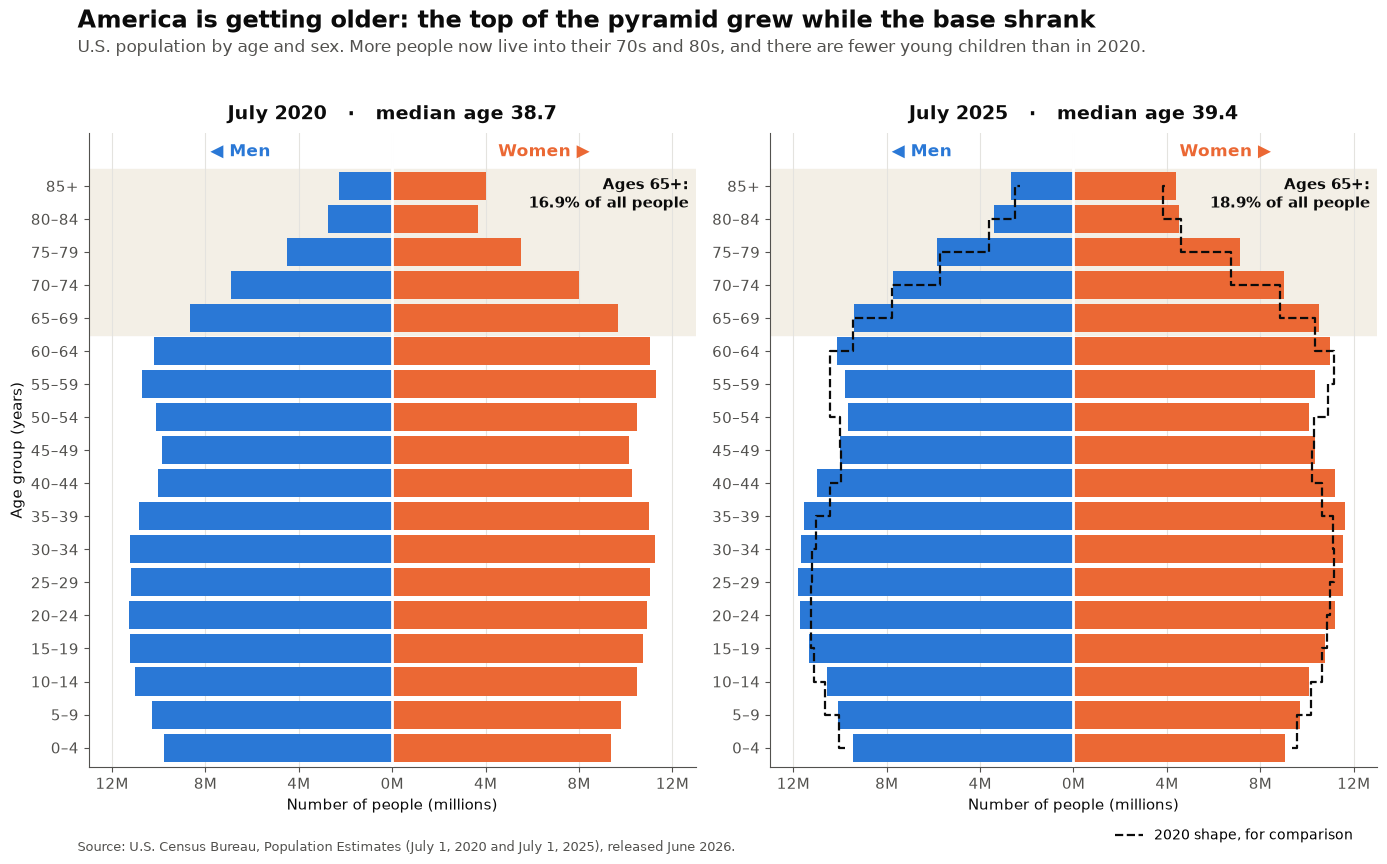

In [10]:
def pyramid_data(year):
    d = tidy[tidy["period"] == year].pivot(index="age_group", columns="sex", values="population")
    return d.loc[AGE_ORDER] / 1e6   # millions, youngest first

p20, p25 = pyramid_data("2020"), pyramid_data("2025")
y = np.arange(len(AGE_ORDER))
limit = 13   # same scale on both charts (millions)
old_rows = [i for i, a in enumerate(AGE_ORDER) if a in ("65–69", "70–74", "75–79", "80–84", "85+")]

share65 = (stages.loc["65 years and over", "Share of all people 2020 (%)"],
           stages.loc["65 years and over", "Share of all people 2025 (%)"])
median = overview.loc["2020", "Median age"], overview.loc["2025", "Median age"]

fig, axes = plt.subplots(1, 2, figsize=(14, 8.5), sharey=True)

for ax, d, year, s65, med in [(axes[0], p20, "2020", share65[0], median[0]),
                              (axes[1], p25, "2025", share65[1], median[1])]:
    # light band behind the 65+ age groups
    ax.axhspan(min(old_rows) - 0.5, max(old_rows) + 0.5, color="#f3efe6", zorder=0)
    ax.text(limit - 0.3, max(old_rows) + 0.3, f"Ages 65+:\n{s65:.1f}% of all people",
            fontsize=11, fontweight="bold", color=INK, va="top", ha="right")

    ax.barh(y, -d["Men"], height=0.85, color=MEN_COLOR, zorder=2)
    ax.barh(y, d["Women"], height=0.85, color=WOMEN_COLOR, zorder=2)

    # 2020 outline on the 2025 chart for comparison
    if year == "2025":
        for side, col in [(-1, "Men"), (1, "Women")]:
            ax.step(side * p20[col].values, y, where="mid", color=INK, lw=1.6, ls="--", zorder=3)

    ax.axvline(0, color="white", lw=2, zorder=3)
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-0.6, len(y) + 0.6)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(4))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{abs(v):.0f}M"))
    ax.set_xlabel("Number of people (millions)")
    ax.grid(axis="x", color=GRID, zorder=1)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(f"July {year}   ·   median age {med:.1f}", fontsize=14, fontweight="bold", color=INK, pad=10)
    ax.text(-limit / 2, len(y) - 0.1, "◀ Men", ha="center", fontsize=12, fontweight="bold", color=MEN_COLOR)
    ax.text(limit / 2, len(y) - 0.1, "Women ▶", ha="center", fontsize=12, fontweight="bold", color=WOMEN_COLOR)

axes[0].set_yticks(y, AGE_ORDER)
axes[0].set_ylabel("Age group (years)")
axes[1].tick_params(labelleft=True)
axes[1].plot([], [], color=INK, lw=1.6, ls="--", label="2020 shape, for comparison")
fig.legend(loc="lower right", bbox_to_anchor=(0.98, 0.0), frameon=False, fontsize=10)

fig.suptitle("America is getting older: the top of the pyramid grew while the base shrank",
             fontsize=17, fontweight="bold", color=INK, x=0.06, ha="left", y=0.995)
fig.text(0.06, 0.945, "U.S. population by age and sex. More people now live into their 70s and 80s, "
         "and there are fewer young children than in 2020.", fontsize=12, color=INK_SOFT, ha="left")
fig.text(0.06, 0.005, "Source: U.S. Census Bureau, Population Estimates (July 1, 2020 and July 1, 2025), released June 2026.",
         fontsize=9, color=INK_SOFT, ha="left")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
plt.show()

**What the pyramids show**
- **The top is heavier in 2025.** Bars for ages 65 and up stick out beyond the dashed 2020 outline, especially ages 75–84. People 65+ went from **16.9% to 18.9%** of the population.
- **The base is narrower.** There are fewer children aged 0–14 in 2025 than in 2020, a result of fewer births.
- **The “bulges” move up.** The large baby-boom group born in the late 1950s–early 1960s has moved from its late 50s into its 60s, and the large group of people in their late 20s–30s (millennials) has moved into its late 30s–40s.
- **Women outnumber men at older ages.** On both charts the orange bars are clearly longer than the blue ones at the top, because women on average live longer.

## 5. Visualization 2 — Which age groups grew or shrank? (2020 → 2025)
**How to read it:** each bar shows how much an age group changed in size between July 2020 and July 2025, as a percent. **Blue bars to the right = the group grew. Orange bars to the left = the group shrank.** Bars are ordered by age, youngest at the bottom, matching the pyramids.

*Percent change* = (people in 2025 − people in 2020) ÷ people in 2020 × 100.

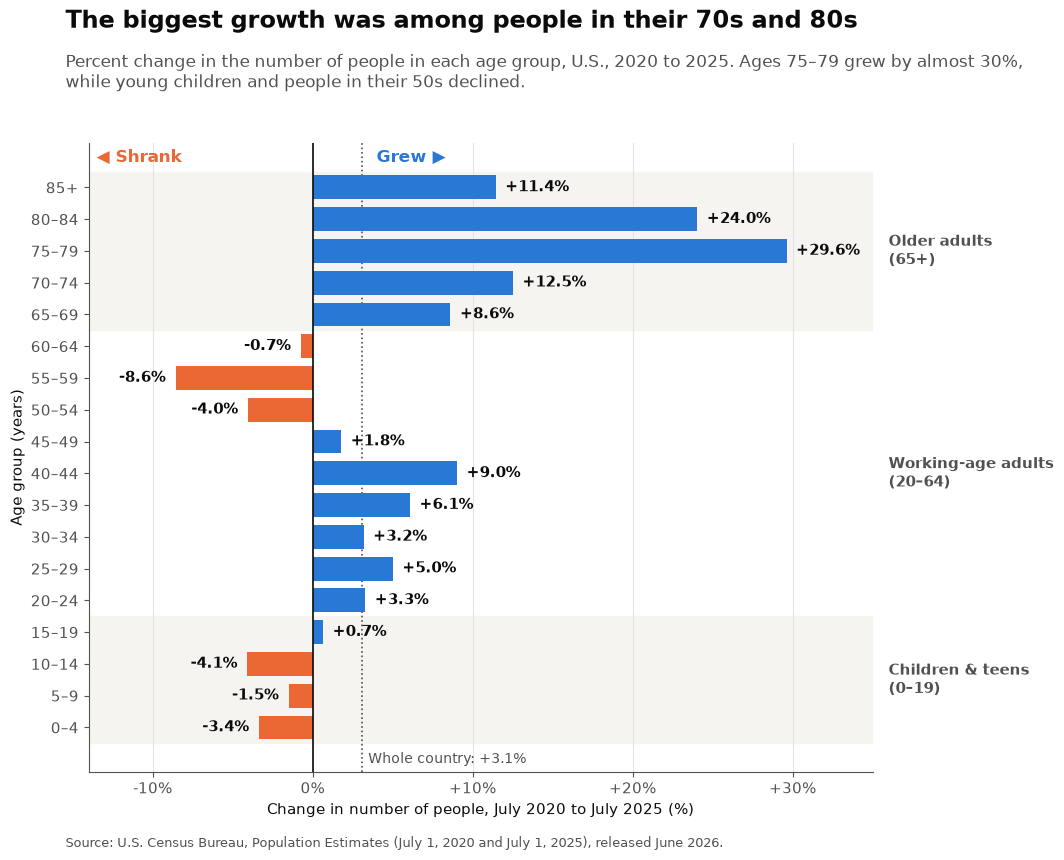

In [11]:
pct = (both["2025"] / both["2020"] - 1) * 100
pct = pct.loc[AGE_ORDER]
total_pct = (tot["2025"] / tot["2020"] - 1) * 100

fig, ax = plt.subplots(figsize=(12, 8.5))
colors = [GROW_COLOR if v >= 0 else SHRINK_COLOR for v in pct]
ax.barh(y, pct, height=0.75, color=colors, zorder=2)

# value labels at the end of every bar
for yi, v in zip(y, pct):
    ax.text(v + (0.6 if v >= 0 else -0.6), yi, f"{v:+.1f}%", va="center",
            ha="left" if v >= 0 else "right", fontsize=10.5, color=INK, fontweight="bold")

# life-stage bands, labeled on the right
bands = [("Children & teens\n(0–19)", 0, 3), ("Working-age adults\n(20–64)", 4, 12), ("Older adults\n(65+)", 13, 17)]
for i, (name, lo, hi) in enumerate(bands):
    if i % 2 == 0:
        ax.axhspan(lo - 0.5, hi + 0.5, color="#f5f4f1", zorder=0)
    ax.text(36, (lo + hi) / 2, name, va="center", ha="left", fontsize=11, color=INK_SOFT, fontweight="bold")

ax.axvline(0, color=INK, lw=1.2, zorder=3)
ax.axvline(total_pct, color=INK_SOFT, lw=1.2, ls=":", zorder=1)
ax.text(total_pct + 0.4, -1.0, f"Whole country: {total_pct:+.1f}%", fontsize=10, color=INK_SOFT, va="center")

ax.set_yticks(y, AGE_ORDER)
ax.set_ylim(-1.4, len(y) + 0.4)
ax.set_xlim(-14, 35)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:+.0f}%" if v else "0%"))
ax.set_xlabel("Change in number of people, July 2020 to July 2025 (%)")
ax.set_ylabel("Age group (years)")
ax.grid(axis="x", color=GRID, zorder=1)
ax.spines[["top", "right"]].set_visible(False)

ax.text(-13.5, len(y) - 0.2, "◀ Shrank", fontsize=12, fontweight="bold", color=SHRINK_COLOR)
ax.text(4, len(y) - 0.2, "Grew ▶", fontsize=12, fontweight="bold", color=GROW_COLOR)

fig.suptitle("The biggest growth was among people in their 70s and 80s",
             fontsize=17, fontweight="bold", color=INK, x=0.06, ha="left", y=0.99)
fig.text(0.06, 0.94, "Percent change in the number of people in each age group, U.S., 2020 to 2025. "
         "Ages 75–79 grew by almost 30%,\nwhile young children and people in their 50s declined.",
         fontsize=12, color=INK_SOFT, ha="left", va="top")
fig.text(0.06, 0.005, "Source: U.S. Census Bureau, Population Estimates (July 1, 2020 and July 1, 2025), released June 2026.",
         fontsize=9, color=INK_SOFT, ha="left")
fig.tight_layout(rect=(0, 0.02, 0.9, 0.9))
plt.show()

In [12]:
# The numbers behind the chart
pd.DataFrame({"2020": both["2020"].loc[AGE_ORDER].map("{:,.0f}".format),
              "2025": both["2025"].loc[AGE_ORDER].map("{:,.0f}".format),
              "Change (people)": (both["2025"] - both["2020"]).loc[AGE_ORDER].map("{:+,.0f}".format),
              "Change (%)": pct.map("{:+.1f}%".format)})

,2020,2025,Change (people),Change (%)
age_group,,,,
0–4,"19,133,927","18,491,867","-642,060",-3.4%
5–9,"20,088,796","19,787,721","-301,075",-1.5%
10–14,"21,498,423","20,620,105","-878,318",-4.1%
15–19,"21,970,317","22,115,280","+144,963",+0.7%
20–24,"22,210,937","22,943,234","+732,297",+3.3%
25–29,"22,227,703","23,342,365","+1,114,662",+5.0%
30–34,"22,503,336","23,221,682","+718,346",+3.2%
35–39,"21,841,296","23,171,303","+1,330,007",+6.1%
40–44,"20,314,489","22,149,712","+1,835,223",+9.0%


**What the bar chart shows**
- **Every older age group grew, and much faster than the country as a whole (+3.1%).** Ages 75–79 grew **+29.6%** and 80–84 grew **+24.0%**, as the first baby boomers reached their late 70s.
- **The youngest children declined:** ages 0–4 fell **3.4%** and 10–14 fell **4.1%**.
- **People in their 50s declined** (55–59 fell **8.6%**). This is the smaller generation born in the late 1960s–early 1970s replacing the larger boomer group as it ages into its 60s.
- **Adults aged 20–44 grew**, with 40–44 up **9.0%**, as the large millennial generation moves through its 30s and 40s.

## 6. Key findings
1. **The U.S. is aging.** The median age rose from **38.7 (2020) to 39.4 (2025)**. People 65 and older grew by about **15%** and now make up nearly **1 in 5 Americans (18.9%)**.
2. **Fewer children.** The under-18 population shrank by about **2%**, and the 0–4 and 10–14 groups each lost more than 3%. The base of the pyramid is getting narrower.
3. **Generations move up the pyramid.** The fastest growth is where the large baby-boom generation is entering its late 70s and 80s; the drop in people in their 50s is the smaller generation that followed.
4. **Older Americans are disproportionately women**, because women tend to live longer than men.
5. **Why it matters:** an older population means more demand for health care, Social Security, and caregiving, while fewer children points toward smaller school enrollments and, later on, a smaller share of working-age adults.

*Limitations:* these are Census Bureau **estimates**, not a full count, and they cover only age and sex. They do not show *why* the changes happened (births, deaths, and immigration all play a part).